# PANDA demo: from an MD trajectory to the contact angle

**PANDA** (`panda_md`) finds the contact angle θ and the interface shape of a liquid confined in a pore from its
one-dimensional density profile. This notebook goes through the whole analysis of a real trajectory, almost every
step being one call of the library:

| Step | Call |
|------|------|
| read the trajectory | `panda.load_trajectory` |
| measure the slit from the wall atoms | `panda.SlitPore.from_trajectory` |
| density profiles over time blocks | `panda.density_profile` |
| bulk density from the 2D map | `panda.density_map(...).bulk_density()` |
| which interface shape is it | `panda.compare_shapes` |
| θ and its error over the blocks | `panda.fit_blocks` |
| are the blocks long enough | `panda.statistical_inefficiency` |
| free, fixed and bounded parameters | `fit(optimize=..., fixed=..., bounds=...)` |
| the shape seen in 2D, axis-centred | `panda.density_map(..., shape=...)` |
| which shape the capillary energy prefers | `panda.stability_diagram` |
| the same calls for a tube, a square and a triangular channel | `panda.CylinderPore`, `SquarePore`, `TrianglePore` |
| save, and the same from the shell | `.save`, `model_dump_json`, `panda profile / fit` |

Systems: a graphite slit pore with water (TIP4P) and n-decane, 10 ns (PANDA_Reborn `graphite_decane_tip4p_1.0`);
a water plug in a carbon nanotube 8 nm wide with benzene, 10 ns (`test-xtc/cylinder_12`). Without these files the
notebook runs on synthetic data of the same structure (a water bridge in a slit, a water plug in a tube).

Run with the kernel of the project environment (`uv sync --all-extras`, kernel `.venv/bin/python`).

In [1]:
import os
from pathlib import Path

import numpy as np

import panda_md as panda
from panda_md.plotting import plot_blocks, plot_density_map, plot_fit, plot_profile, plot_stability

SYSTEM = Path(os.environ.get("PANDA_REBORN_DIR", "/mnt/c/Phystech/Computing_Physics_Center/Projects/PANDA_Reborn"))
TOPOLOGY = SYSTEM / "graphite_decane_tip4p_1.0" / "graphite_decane_tip4p.tpr"
TRAJECTORY = SYSTEM / "graphite_decane_tip4p_1.0" / "graphite_decane_tip4p.xtc"
WALLS, WATER, DECANE = "resname GRAPHITE", "resname WATER and name OW", "resname DECAN*"
START, BLOCK = "2 ns", "1 ns"  # equilibration to skip, length of a time block
SHORT_BLOCK, SHORT_STRIDE = "100 ps", 2  # short blocks for the statistical inefficiency of θ
CNT_TOPOLOGY = SYSTEM / "test-xtc" / "cylinder_12" / "cnt_benzene_tip4p.tpr"
CNT_TRAJECTORY = SYSTEM / "test-xtc" / "cylinder_12" / "cnt_benzene_tip4p_last10ns.xtc"
OUT = Path("demo_results")
OUT.mkdir(exist_ok=True)
print(f"panda-md {panda.__version__}")

panda-md 0.1.0


## 1. Trajectory and pore

The pore is measured in a frame of the trajectory: H is the empty gap between the wall atoms (across the periodic
boundary if needed), L and k come from the box. `liquid=` picks the gap that holds the liquid if the box has a
vacuum slab.

In [2]:
if TOPOLOGY.exists():
    trajectory = panda.load_trajectory(TOPOLOGY, TRAJECTORY)
else:  # no MD files: a synthetic trajectory with the same structure — a water bridge (roll) in a slit
    truth = panda.SlitPore(width_nm=8.27, length_nm=17.27, base_aspect_ratio=0.3).interface("roll")
    trajectory = panda.synthetic_trajectory(truth, {"theta": 165.0, "delta": 0.05, "phi": 0.49},
                                            density_bulk_per_nm3=33.1, frame_count=200, seed=0)
    WALLS, WATER, DECANE, START, BLOCK = "walls", "liquid", None, "0 ps", "250 ps"
    SHORT_BLOCK, SHORT_STRIDE = "20 ps", 1

pore = panda.SlitPore.from_trajectory(trajectory, walls=WALLS, liquid=WATER, time=START)
pore

slit pore: wall_selection = 'resname GRAPHITE', width_nm = 8.269, length_nm = 17.271, base_aspect_ratio = 0.296923

## 2. Density profiles over time blocks

One histogram per block of `BLOCK`; the mean over blocks is the profile to fit, the spread over blocks is its error.
The profile is centred on the pore (the middle between the walls, found in every frame) and flipped if the liquid
sits at the upper wall.

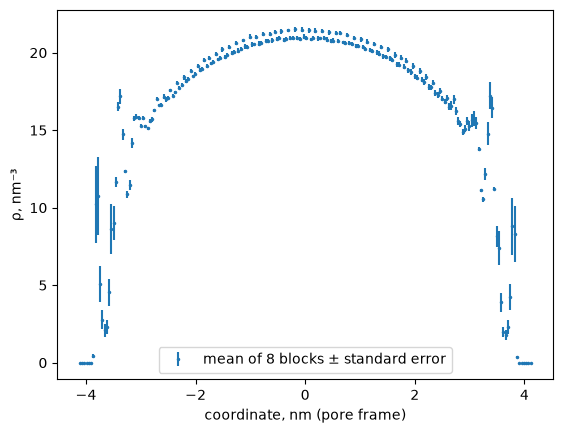

In [3]:
profiles = panda.density_profile(trajectory, pore, WATER, start=START, block=BLOCK)
plot_profile(profiles);

## 3. Bulk density from the 2D map

The fit compares ρ / ρ_bulk with the model, so it needs the bulk density of the liquid. The 2D map x–z shows the
liquid in the pore; `bulk_density()` takes the median density in the core of the phase in the middle of the slit,
away from the layering at the walls.

ρ_bulk of water ≈ 33.14 nm⁻³


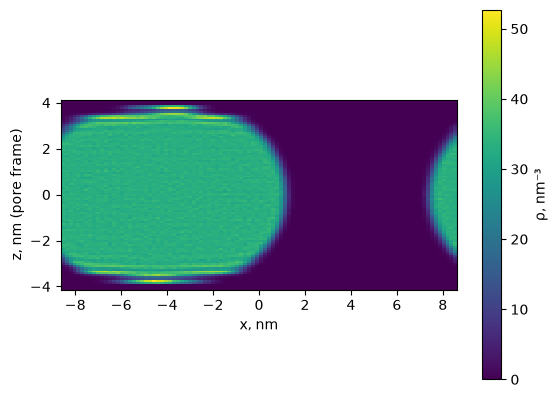

In [4]:
water_map = panda.density_map(trajectory, pore, WATER, start=START, stride=5)
rho_bulk = water_map.bulk_density()
print(f"ρ_bulk of water ≈ {rho_bulk:.2f} nm⁻³")
plot_density_map(water_map);

## 4. Which interface shape?

Every shape of the pore is fitted with the same settings and ranked by the loss. Shapes that cannot hold this volume
fraction are listed with the reason; shapes the profile cannot tell apart would be marked with «≈».

In [5]:
spec = panda.FitSpec(density_bulk_per_nm3=rho_bulk)
comparison = panda.compare_shapes(pore, profiles.mean(), spec)
print(comparison)

slit: shape comparison
  roll                     loss = 0.02614  theta = 171.1, delta = 0.0625, phi = 0.4865, shift = 0
  worm                     loss = 0.08421  theta = 116.4, delta = 0.03294, phi = 0.4865, shift = 0
  layer                    loss = 0.3638  delta = 0, phi = 0.6568, shift = 0
  doughnut                 skipped: shape 'doughnut', regime non_wetting: no starting point lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.4865, shift = 0; check the fixed values and the bounds
  droplet                  skipped: shape 'droplet', regime non_wetting: no starting point lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.4865, shift = 0; check the fixed values and the bounds
  perforation              skipped: shape 'perforation', regime non_wetting: no starting point lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.4865, shift = 0; check the fixed values and the bounds


## 5. Contact angle

The best shape gives θ (free with δ; φ is taken from ∫ρ). The summary lists free and fixed parameters and any
problem flags (a parameter at its bound, θ pressed to 90°, …).

slit/roll  regime: non_wetting  loss: 0.02614
   theta = 171.065  (free)
   delta = 0.0625  (free)
     phi = 0.486492  (fixed)
   shift = 0  (fixed)


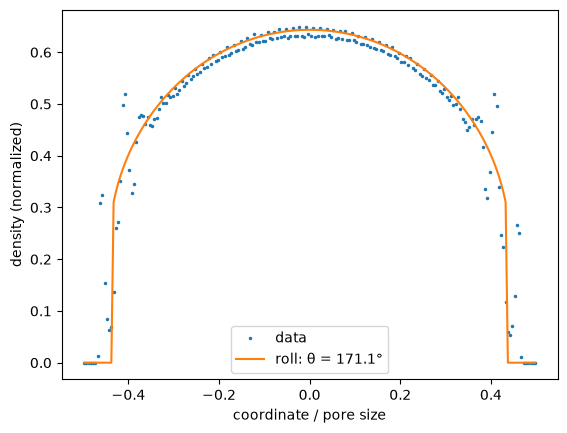

In [6]:
result = comparison.best
print(result)
plot_fit(result);

## 6. θ over time blocks: the error of the angle

Each block is fitted separately; the spread over the blocks is the honest error of θ (if the blocks are longer
than the correlation time — `panda.statistical_inefficiency` checks that). Near θ = 180° the profile depends weakly
on θ, so the spread is large: report θ with it.

slit/roll: 8 block(s)
block t, ps                 theta      delta        phi      shift       loss  flags
   0  2000–2998            176.36   0.033103    0.48649          0    0.02397  
   1  3000–3998            176.11     0.0375    0.48649          0    0.02687  
   2  4000–4998             178.2     0.0375    0.48649          0    0.02782  
   3  5000–5998            166.25     0.0625    0.48649          0    0.02737  
   4  6000–6998               180     0.0625    0.48649          0    0.02449  at bound: theta
   5  7000–7998            167.38     0.0675    0.48649          0    0.02363  
   6  8000–8998            166.06     0.0675    0.48649          0    0.02519  
   7  9000–9998            154.96     0.0775    0.48649          0    0.02197  
mean ± standard error: theta = 170.67 ± 3, delta = 0.0557 ± 0.006, phi = 0.48649 ± 0, shift = 0 ± 0


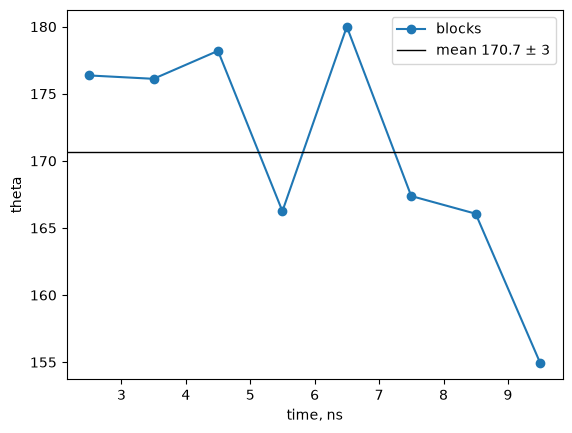

In [7]:
model = pore.interface(result.shape_name)
blocks = panda.fit_blocks(model, profiles, spec)
print(blocks)
plot_blocks(blocks);

### Are the blocks long enough?

θ fitted over short blocks forms a time series. Its statistical inefficiency s is the number of consecutive values
per independent one: θ decorrelates over about s short blocks. Blocks much longer than that give independent
estimates, and only then is the error over the blocks above honest.

In [8]:
short = panda.density_profile(trajectory, pore, WATER, start=START, block=SHORT_BLOCK, stride=SHORT_STRIDE)
series = panda.fit_blocks(model, short, spec).values("theta")
inefficiency = panda.statistical_inefficiency(series).plateau()
print(f"{short.block_count} blocks of {SHORT_BLOCK}: s ≈ {inefficiency:.1f} — θ decorrelates over about "
      f"{inefficiency:.0f} × {SHORT_BLOCK}; the blocks above are {BLOCK} long")

80 blocks of 100 ps: s ≈ 2.2 — θ decorrelates over about 2 × 100 ps; the blocks above are 1 ns long


## 7. Controlling the fit

Every parameter can be freed, fixed or bounded with the same keywords for every shape: `optimize`, `fixed`,
`bounds` (and `loss`, `regime`, `window`, `normalization`). Near 180° θ trades off against δ: fixing δ pushes θ to its
bound, and the result says so with a flag. Freeing `shift` lets the fit move the model along the profile axis if the
walls were found slightly off.

In [9]:
variants = {
    "θ, δ free (default)": {},
    "δ fixed at 0.05": {"optimize": ["theta"], "fixed": {"delta": 0.05}},
    "θ within 150–175°": {"bounds": {"theta": (150.0, 175.0)}},
    "θ, δ and shift free": {"optimize": ["theta", "delta", "shift"]},
}
for label, options in variants.items():
    fitted = model.fit(profiles.mean(), density_bulk_per_nm3=rho_bulk, **options)
    values = ", ".join(f"{name} = {value:.4g}" for name, value in fitted.values.items())
    print(f"{label:<21} {values}  loss = {fitted.loss:.4g}  {'; '.join(fitted.problems())}")

θ, δ free (default)   theta = 171.1, delta = 0.0625, phi = 0.4865, shift = 0  loss = 0.02614  
δ fixed at 0.05       theta = 180, delta = 0.05, phi = 0.4865, shift = 0  loss = 0.02846  at bound: theta
θ within 150–175°     theta = 171.1, delta = 0.0625, phi = 0.4865, shift = 0  loss = 0.02614  


θ, δ and shift free   theta = 177.9, delta = 0.05, phi = 0.4865, shift = -0.0125  loss = 0.02558  


## 8. The shape in 2D, axis-centred

A roll wanders along the walls during the run. Axial centering puts its axis at x = 0 in every frame, so the map
shows the bridge itself rather than a smeared average — a direct check of the shape the fit has chosen.

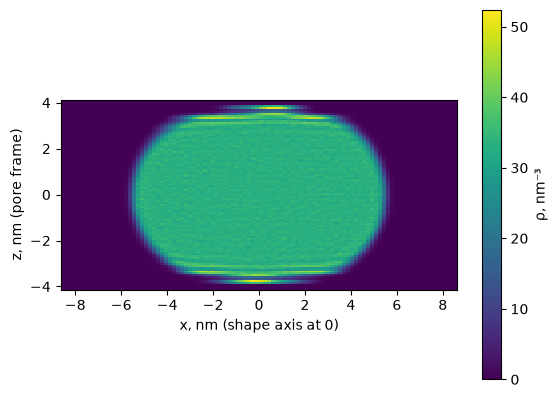

In [10]:
centred = panda.density_map(trajectory, pore, WATER, shape=result.shape_name, start=START, stride=5)
plot_density_map(centred);

## 9. Stability diagram at the measured θ and δ

For every pore length l = L / H and volume fraction φ the shape with the lowest capillary energy S_LV − cos θ·S_SL
wins. The cross marks this pore and this liquid.

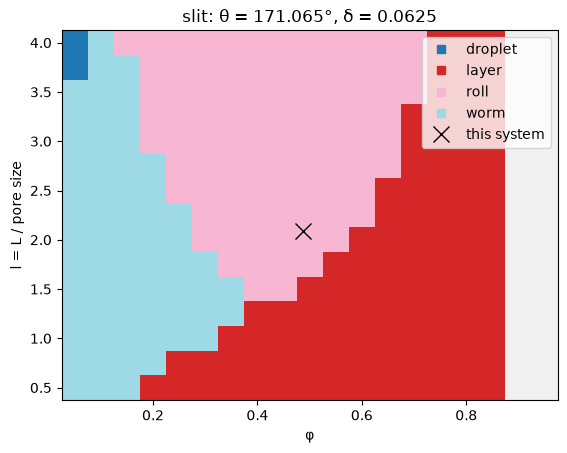

In [11]:
theta, delta, phi = (result.values[name] for name in ("theta", "delta", "phi"))
diagram = panda.stability_diagram(pore, contact_angle_deg=theta, wall_layer=delta,
                                  volume_fractions=np.linspace(0.05, 0.95, 19), length_ratios=np.linspace(0.5, 4.0, 15))
axes = plot_stability(diagram)
axes.plot(phi, pore.length_nm / pore.width_nm, "kx", markersize=12, label="this system")
axes.legend();

## 10. The second liquid: decane

The same three calls. Decane wets graphite (it lies on the walls under the water bridge): formulas for θ < 90° are
not derived for the slit shapes, so the fit stops at the regime boundary and says so with a flag instead of giving a
false angle.

In [12]:
if DECANE is None:
    print("synthetic trajectory: no second liquid")
else:
    decane = panda.density_profile(trajectory, pore, DECANE, start=START, block=BLOCK, per="molecule", stride=5)
    decane_bulk = panda.density_map(trajectory, pore, DECANE, start=START, stride=5, per="molecule").bulk_density()
    decane_fit = pore.interface("roll").fit(decane.mean(), density_bulk_per_nm3=decane_bulk)
    print(f"ρ_bulk of decane ≈ {decane_bulk:.2f} molecules/nm³; φ(water) + φ(decane) = "
          f"{phi + decane_fit.values['phi']:.3f}")
    print(decane_fit)

ρ_bulk of decane ≈ 3.17 molecules/nm³; φ(water) + φ(decane) = 0.958
slit/roll  regime: non_wetting  loss: 0.1989
   theta = 90.5  (free)
   delta = 0.0375  (free)
     phi = 0.471556  (fixed)
   shift = 0  (fixed)
  ! θ at 90° (regime boundary)


## 11. Other pores: the same calls

Every pore type works the same way: a pore with its dimensions (or measured from the wall atoms), shapes registered
with it, the same fit, shape comparison and blocks. A cylindrical pore — a water plug (`capsule`) in a carbon
nanotube with benzene around it — is measured from the wall atoms like the slit: the tube axis lies opposite the
widest empty gap of the wall atoms, D is twice the distance from the axis to the nearest wall atom. ρ_bulk is the one
measured in the slit above: the same TIP4P water.

cylinder pore: wall_selection = 'resname GRAPH*', diameter_nm = 7.999, length_nm = 16, layer_width_nm = 11.345
cylinder/capsule  regime: non_wetting  loss: 0.01056
   theta = 128.755  (free)
   delta = 0.0811858  (free)
     phi = 0.444216  (fixed)
   shift = 0  (fixed)


θ over 10 blocks: 126.2 ± 2.3° (spread 7.3°)


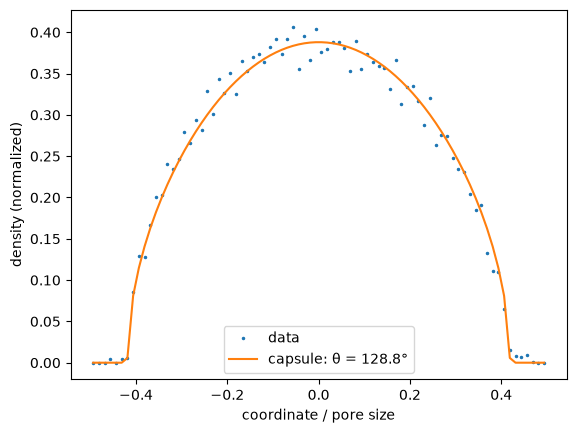

In [13]:
if CNT_TOPOLOGY.exists():
    tube_trajectory = panda.load_trajectory(CNT_TOPOLOGY, CNT_TRAJECTORY)
    tube_start = float(tube_trajectory.times_ps()[0])
    tube = panda.CylinderPore.from_trajectory(tube_trajectory, walls="resname GRAPH*", liquid=WATER, time=tube_start)
    tube_profiles = panda.density_profile(tube_trajectory, tube, WATER, start=tube_start, block="1 ns", stride=5,
                                          bins=80)
    tube_profile = tube_profiles.mean()
else:  # no MD files: a synthetic water plug in a tube of the same size
    tube = panda.CylinderPore(diameter_nm=8.0, length_nm=16.0, layer_width_nm=11.3)
    tube_profiles = None
    tube_profile = panda.synthetic_profile(tube.interface("capsule"), {"theta": 127.0, "delta": 0.08, "phi": 0.42},
                                           density_bulk_per_nm3=rho_bulk, bin_count=80, noise_std=0.01, seed=0)
print(tube)
capsule = tube.interface("capsule")
tube_fit = capsule.fit(tube_profile, density_bulk_per_nm3=rho_bulk)
print(tube_fit)
if tube_profiles is not None:
    tube_blocks = panda.fit_blocks(capsule, tube_profiles, spec)
    print(f"θ over {tube_profiles.block_count} blocks: {tube_blocks.mean('theta'):.1f} ± "
          f"{tube_blocks.sem('theta'):.1f}° (spread {tube_blocks.std('theta'):.1f}°)")
plot_fit(tube_fit);

Square and triangular channels have no MD runs yet, so here a synthetic profile of a known shape with 1 % noise
stands in for the data: `compare_shapes` finds the shape and recovers the angle. Shapes without a derived profile
take part only in stability diagrams and are listed as such.

In [14]:
channels = [
    (panda.SquarePore(side_nm=4.0, length_nm=12.0, layer_width_nm=6.0), "droplet_w1c0",
     {"theta": 130.0, "delta": 0.03, "phi": 0.1}),
    (panda.TrianglePore(side_nm=5.0, length_nm=12.0, layer_width_nm=6.0), "capsule_w3c0",
     {"theta": 150.0, "delta": 0.02, "phi": 0.5}),
]
for channel, shape, truth in channels:
    synthetic = panda.synthetic_profile(channel.interface(shape), truth, density_bulk_per_nm3=33.0, noise_std=0.01,
                                        seed=1)
    ranking = panda.compare_shapes(channel, synthetic, panda.FitSpec(density_bulk_per_nm3=33.0))
    print(f"true shape: {shape}, θ = {truth['theta']:g}°")
    print(ranking, end="\n\n")

true shape: droplet_w1c0, θ = 130°
square: shape comparison
  droplet_w1c0             loss = 0.005941  theta = 130.2, delta = 0.0275, phi = 0.1007, shift = 0
  droplet_w2c1             loss = 0.007244  theta = 126, delta = 0.0275, phi = 0.1007, shift = 0
  droplet_w2c0             loss = 0.00847  theta = 135, delta = 0.002502, phi = 0.1007, shift = 0
  capsule_w4c0             loss = 0.04183  theta = 175.6, delta = 0.08492, phi = 0.1007, shift = 0
  filament_w2c1            loss = 0.04936  theta = 53.87, delta = 0.0975, phi = 0.1007, shift = 0
  filament_w1c0            loss = 0.05209  theta = 180, delta = 0.09593, phi = 0.1007, shift = 0
  filament_w0c0            loss = 0.0528  delta = 0, phi = 0.03375, shift = 0
  filament_w0c0_square     loss = 0.05281  delta = 0, phi = 0.02723, shift = 0
  filament_w3c2            loss = 0.09246  theta = 138.3, delta = 0.09751, phi = 0.1007, shift = 0
  filament_w2c0_opp        loss = 0.09769  theta = 116.3, delta = 0.1, phi = 0.1007, shift = 0
 

true shape: capsule_w3c0, θ = 150°
triangle: shape comparison
  capsule_w3c0             loss = 0.005742  theta = 150.5, delta = 0.01985, phi = 0.5006, shift = 0
  filament_w3c0            loss = 0.02875  theta = 137.8, delta = 0.0498, phi = 0.5006, shift = 0
  filament_w2c0            loss = 0.02959  theta = 163.2, delta = 0.02382, phi = 0.5006, shift = 0
  filament_w1c0            loss = 0.03022  theta = 169.9, delta = 0.01949, phi = 0.5006, shift = 0
  filament_w0c0            loss = 0.03135  delta = 0, phi = 0.4786, shift = 0
  filament_w3c1            loss = 0.04754  theta = 180, delta = 0.06279, phi = 0.5006, shift = 0
  filament_w2c1            loss = 0.0488  theta = 119.5, delta = 0.06444, phi = 0.5006, shift = 0
  capsule_w3c3             loss = 0.05806  theta = 120, delta = 0.04979, phi = 0.5006, shift = 0
  filament_w3c2            loss = 0.06024  theta = 148.2, delta = 0.08105, phi = 0.5006, shift = 0
  filament_w0c0_triangle   loss = 0.06653  delta = 0, phi = 0.5004, shift

## 12. Save the results

Profiles, maps and results are plain files: `.npz` / `.csv` for data, JSON for the pore and the fit (all of them
record the PANDA version). They load back with `panda.ProfileSet.load`, `panda.FitResult.model_validate_json`, ….

In [15]:
from panda_md.plotting import save_fit_figure

profiles.save(OUT / "water_profiles.npz")
(OUT / "pore.json").write_text(pore.model_dump_json(indent=2))
(OUT / "water_fit.json").write_text(result.model_dump_json(indent=2))
save_fit_figure(result, OUT / "water_fit.png")
sorted(path.name for path in OUT.iterdir())

['cli_result.json',
 'pore.json',
 'water_fit.json',
 'water_fit.png',
 'water_profiles.npz']

## 13. The same from the shell

The command line builds the same settings and calls the same functions. Without dimensions `panda profile` measures
the slit from the walls and saves it for `panda fit`; `--shape auto` compares all shapes, `--blocks` fits every block.
Here it runs on the profiles saved above (`panda profile TOP TRAJ ...` would compute them from the trajectory).

In [16]:
import shlex
import subprocess
import sys

command = [sys.executable, "-m", "panda_md", "fit", str(OUT / "water_profiles.npz"),
           "--pore-file", str(OUT / "pore.json"), "--shape", "auto", "--rho-bulk", f"{rho_bulk:.3f}", "--blocks",
           "-o", str(OUT / "cli_result.json")]
print("$ panda " + shlex.join(command[3:]))
completed = subprocess.run(command, capture_output=True, text=True)
print(completed.stdout, completed.stderr, f"exit code {completed.returncode} (2: a block has a problem flag)", sep="")

$ panda fit demo_results/water_profiles.npz --pore-file demo_results/pore.json --shape auto --rho-bulk 33.138 --blocks -o demo_results/cli_result.json


slit: shape comparison
  roll                     loss = 0.02614  theta = 171.1, delta = 0.0625, phi = 0.4865, shift = 0
  worm                     loss = 0.08421  theta = 116.4, delta = 0.03294, phi = 0.4865, shift = 0
  layer                    loss = 0.3638  delta = 0, phi = 0.6568, shift = 0
  doughnut                 skipped: shape 'doughnut', regime non_wetting: no starting point lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.4865, shift = 0; check the fixed values and the bounds
  droplet                  skipped: shape 'droplet', regime non_wetting: no starting point lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.4865, shift = 0; check the fixed values and the bounds
  perforation              skipped: shape 'perforation', regime non_wetting: no starting point lies in the existence domain at theta ∈ [90.5, 180], delta ∈ [0, 0.1], phi = 0.4865, shift = 0; check the fixed values and the bounds
best shape: roll
slit/r

## Where next

- `examples/test_panda.ipynb` — a full check of the library (synthetic data and three real systems, PASS / FAIL).
- `examples/05_custom_shape.py` — add your own interface shape from a script.
- `panda shapes` — every pore type, shape, parameter and bound; `panda run panda.toml` — profile + fit from one file.
- Documentation: `make docs` (guide and API reference).